# 00 · Data checks

**Question:** Is the match data complete and correct, and does home advantage look different in 2020-21 even before any modelling?

Run this before any analysis. A model can't fix bad data.

   # Takeaway: home advantage fell in every league once stadiums emptied, but the drop
   # shows in different seasons because leagues stopped and restarted at different times.

In [2]:
%load_ext autoreload
%autoreload 2


import matplotlib.pyplot as plt

from ghost_games.data import load_matches
from ghost_games.outcomes import add_outcomes

In [3]:
matches = add_outcomes(load_matches("../data/raw"))
print(matches.shape)
matches.head()

(14507, 18)


,league,date,home_team,away_team,home_goals,away_goals,home_yellows,away_yellows,home_reds,away_reds,home_fouls,away_fouls,season,goal_diff,home_points,points_diff,card_gap,foul_gap
0,D1,2015-08-14,Bayern Munich,Hamburg,5.0,0.0,2.0,2.0,0.0,0.0,10.0,12.0,2015-16,5.0,3,3,0.0,2.0
1,D1,2015-08-15,Augsburg,Hertha,0.0,1.0,1.0,2.0,1.0,1.0,20.0,22.0,2015-16,-1.0,0,-3,1.0,2.0
2,D1,2015-08-15,Darmstadt,Hannover,2.0,2.0,1.0,2.0,0.0,0.0,21.0,22.0,2015-16,0.0,1,0,1.0,1.0
3,D1,2015-08-15,Dortmund,M'gladbach,4.0,0.0,0.0,1.0,0.0,0.0,13.0,14.0,2015-16,4.0,3,3,1.0,1.0
4,D1,2015-08-15,Leverkusen,Hoffenheim,2.0,1.0,1.0,0.0,0.0,0.0,12.0,18.0,2015-16,1.0,3,3,-1.0,6.0


## 1. Sanity checks
Each `assert` stops the notebook if something is wrong, instead of letting bad data reach the model.

In [4]:
counts = matches.groupby(["league", "season"]).size()
expected = {"D1": 306, "E0": 380, "SP1": 380, "I1": 380, "F1": 380}
# compare each count with the expected number for its league
expected_counts = counts.index.get_level_values("league").map(expected)
odd = counts[counts.to_numpy() != expected_counts.to_numpy()]
print("League-seasons with an unusual match count:")
print(odd)

assert not matches.duplicated(["league", "date", "home_team", "away_team"]).any()
assert (matches[["home_goals", "away_goals"]] >= 0).all().all()
assert matches["date"].between("2015-07-01", "2023-07-01").all()

League-seasons with an unusual match count:
league  season 
F1      2019-20    279
dtype: int64


## 2. First look: home advantage per season
Mean home goal difference. 0 would mean no home advantage.

In [5]:
by_season = matches.pivot_table(
    index="season", columns="league", values="goal_diff", aggfunc="mean"
)
by_season.style.format("{:+.2f}").background_gradient(cmap="RdYlGn", axis=None)

league,D1,E0,F1,I1,SP1
season,,,,,
2015-16,+0.30,+0.28,+0.35,+0.37,+0.49
2016-17,+0.45,+0.39,+0.48,+0.37,+0.38
2017-18,+0.41,+0.38,+0.34,+0.23,+0.40
2018-19,+0.40,+0.32,+0.38,+0.29,+0.32
2019-20,+0.11,+0.31,+0.47,+0.21,+0.39
2020-21,+0.32,+0.01,+0.03,+0.20,+0.23
2021-22,+0.41,+0.21,+0.36,+0.14,+0.34
2022-23,+0.54,+0.42,+0.17,+0.26,+0.40


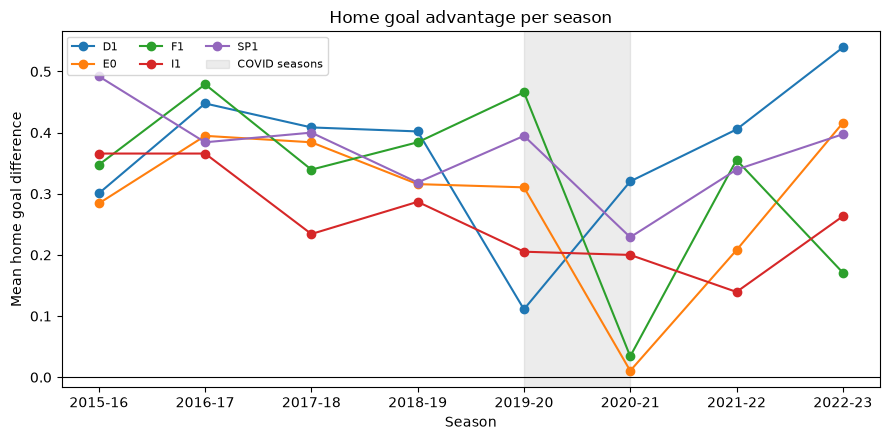

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for league in by_season.columns:
    ax.plot(by_season.index, by_season[league], marker="o", label=league)
ax.axvspan("2019-20", "2020-21", color="grey", alpha=0.15, label="COVID seasons")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Home goal advantage per season")
ax.set_xlabel("Season")
ax.set_ylabel("Mean home goal difference")
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()
# Takeaway: TODO, write one sentence after you see the chart

## 3. Your turn
Before reading on, write down:
1. Which league lost the most home advantage in 2020-21?
2. Did it come back in 2021-22?
3. Can a season-level average answer *why*? (Hint: what else changed that season?)